# Bank Marketing Campaign Response Analysis & Prediction

## 4. Machine Learning

### Objective

Develop a classification model to predict whether a customer will subscribe to a term deposit based on their demographic, financial, and campaign-related characteristics.

### Machine Learning Approach

1. Load and inspect the dataset.
2. Separate the input features and target variable.
3. Split the data into training and testing sets.
4. Preprocess numerical and categorical features.
5. Train classification models.
6. Evaluate model performance using appropriate metrics.
7. Compare models and identify the most suitable approach.

### Target Variable

The target variable is `y`, which indicates whether the customer subscribed to a term deposit (`yes` or `no`).


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("../data/bank-full.csv",sep=';')

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
df.shape

(45211, 17)

In [6]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [7]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [8]:
df['y'].value_counts(normalize=True)*100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

In [9]:
X=df.drop('y',axis=1)
y=df['y']

In [10]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (45211, 16)
Target shape: (45211,)


In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (36168, 16)
X_test: (9043, 16)
y_train: (36168,)
y_test: (9043,)


In [14]:
numerical_cols = X_train.select_dtypes(include='number').columns

categorical_cols = X_train.select_dtypes(include=['str', 'object', 'category']).columns

print("Numerical columns:")
print(list(numerical_cols))

print("\nCategorical columns:")
print(list(categorical_cols))

Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [16]:
numerical_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

In [17]:
categorical_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [18]:
preprocessor = ColumnTransformer(transformers=[('num', numerical_pipeline, numerical_cols),('cat', categorical_pipeline, categorical_cols)])

In [19]:
from sklearn.linear_model import LogisticRegression

In [20]:
model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000, random_state=42))])

In [21]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

In [22]:
y_pred = model.predict(X_test)

In [23]:
print(y_pred[:10])

['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.901249585314608
Model Accuracy (%): 90.12495853146079


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          no       0.92      0.97      0.95      7985
         yes       0.64      0.35      0.45      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.89      0.90      0.89      9043



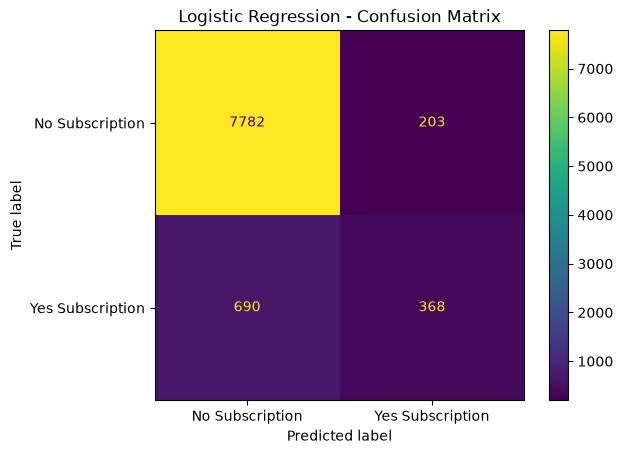

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=['no', 'yes'])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Subscription', 'Yes Subscription']
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Logistic Regression: Model Evaluation

The Logistic Regression model achieved an accuracy of **90.12%** on the test dataset. However, accuracy alone is insufficient to evaluate this model because the dataset is imbalanced, with approximately 88.3% of customers belonging to the non-subscriber class.

The model achieved a recall of approximately **34.8% for the subscriber class (`yes`)**, identifying 368 out of 1,058 actual subscribers. It missed 690 actual subscribers by incorrectly predicting that they would not subscribe.

The precision for the subscriber class was approximately 64.4%, indicating that about 64% of customers predicted to subscribe actually subscribed.

**Conclusion:** Although the model achieved high overall accuracy, its ability to identify potential subscribers needs improvement. Therefore, we will evaluate a Random Forest classifier and compare its performance using precision, recall, F1-score, and the confusion matrix.


In [27]:
from sklearn.ensemble import RandomForestClassifier

In [28]:
rf_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced',n_jobs=-1))])

### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear relationships and interactions between customer characteristics.

We use `class_weight='balanced'` to account for the imbalance between subscribers and non-subscribers. The model will be evaluated using precision, recall, F1-score, and accuracy to determine whether it improves upon Logistic Regression.


In [29]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

In [30]:
rf_y_pred = rf_model.predict(X_test)

In [31]:
print(rf_y_pred[:10])

['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [32]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_y_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

Random Forest Accuracy: 0.8989273471193188
Random Forest Accuracy (%): 89.89273471193188


In [33]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_y_pred))

              precision    recall  f1-score   support

          no       0.95      0.93      0.94      7985
         yes       0.56      0.65      0.60      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.79      0.77      9043
weighted avg       0.91      0.90      0.90      9043



### Random Forest Model Evaluation

The Random Forest model achieved an accuracy of approximately 89.89%.

For the `yes` class, the model achieved:
- Precision: 0.56
- Recall: 0.65
- F1-score: 0.60

Although its overall accuracy is slightly lower than Logistic Regression, Random Forest improved recall from approximately 35% to 65%. This means it identifies a larger proportion of customers who actually subscribe to the term deposit.

However, its lower precision indicates that more customers predicted to subscribe do not actually subscribe.

Therefore, Random Forest currently performs better at identifying potential subscribers, while the final model selection should consider the business objective and other evaluation metrics.

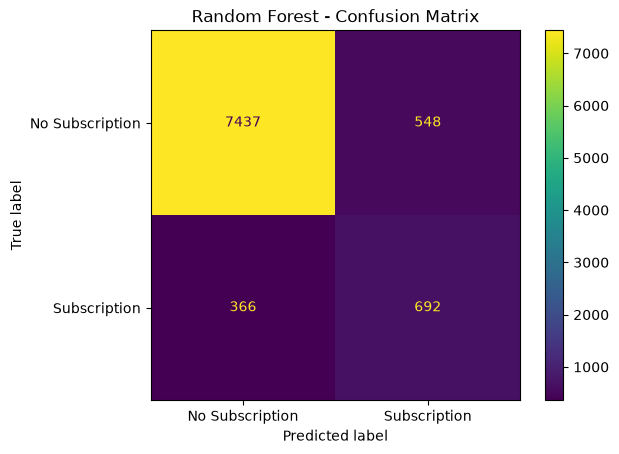

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_y_pred,
    labels=['no', 'yes'],
    display_labels=['No Subscription', 'Subscription']
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

### Random Forest Confusion Matrix Interpretation

The confusion matrix shows the following results:

- True Negatives: 7,437
- False Positives: 548
- False Negatives: 366
- True Positives: 692

The model correctly identified 692 customers who subscribed to the term deposit and 7,437 customers who did not subscribe.

However, it incorrectly classified 548 non-subscribers as subscribers and missed 366 actual subscribers.

The model achieved approximately 65.4% recall for the `yes` class, meaning it identified around 65% of the actual subscribers in the test dataset.

These results suggest that the Random Forest model identifies more potential subscribers than Logistic Regression, although some predictions are incorrect.

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (model, y_pred),
    "Random Forest": (rf_model, rf_y_pred)
}

results = []

for name, (trained_model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Yes)": precision_score(
            y_test, predictions, pos_label="yes"
        ),
        "Recall (Yes)": recall_score(
            y_test, predictions, pos_label="yes"
        ),
        "F1-score (Yes)": f1_score(
            y_test, predictions, pos_label="yes"
        )
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
0,Logistic Regression,0.901,0.644,0.348,0.452
1,Random Forest,0.899,0.558,0.654,0.602


### Model Comparison and Initial Selection

Two classification algorithms were evaluated: Logistic Regression and Random Forest.

Logistic Regression achieved an accuracy of 90.1%, while Random Forest achieved 89.9%. Although Logistic Regression performed slightly better in terms of accuracy and precision, Random Forest achieved a higher recall of 65.4% and an F1-score of 0.602 for the `yes` class.

Since identifying potential subscribers is an important business objective, Random Forest is the preferred candidate at this stage.

However, this is an initial selection. Further evaluation and feature analysis are required before finalizing the model for deployment.


### Model Improvement: Excluding Call Duration

The `duration` feature represents the duration of the last contact with a customer. This information may not be available when a bank is deciding which customers to contact.

To make the model more suitable for predicting potential subscribers before a call, we will train another Random Forest model without the `duration` feature.

We will compare its performance with the original Random Forest model to understand how excluding this feature affects prediction quality.


In [36]:
X_no_duration = X.drop(columns=['duration'])

X_train_nd, X_test_nd, y_train_nd, y_test_nd = train_test_split(X_no_duration, y, test_size=0.2, random_state=42, stratify=y)

numerical_columns_nd =X_train_nd.select_dtypes(include='number').columns

categorical_columns_nd=X_train_nd.select_dtypes(include=['str','object','category']).columns

print("Numerical features:",list(numerical_columns_nd))
print("Categorical features:", list(categorical_columns_nd))
print("Training data shape:", X_train_nd.shape)
print("Testing data shape:", X_test_nd.shape)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Training data shape: (36168, 15)
Testing data shape: (9043, 15)


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [39]:
numerical_pipeline_nd = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

categorical_pipeline_nd = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor_nd = ColumnTransformer(
    transformers=[('num', numerical_pipeline_nd, numerical_columns_nd),('cat', categorical_pipeline_nd, categorical_columns_nd)])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model_nd = Pipeline(steps=[('preprocessor', preprocessor_nd),
    ('classifier', RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced',n_jobs=-1))])

rf_model_nd.fit(X_train_nd, y_train_nd)

print("Random Forest model without duration trained successfully.")

Random Forest model without duration trained successfully.


In [41]:
from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix)

rf_y_pred_nd = rf_model_nd.predict(X_test_nd)

accuracy_nd = accuracy_score(y_test_nd, rf_y_pred_nd)

print("Random Forest Accuracy (without duration):", round(accuracy_nd, 4))
print("Accuracy (%):", round(accuracy_nd * 100, 2), "%")

Random Forest Accuracy (without duration): 0.8795
Accuracy (%): 87.95 %


In [42]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report (Without Duration)")
print(classification_report(y_test_nd, rf_y_pred_nd))

Random Forest Classification Report (Without Duration)
              precision    recall  f1-score   support

          no       0.92      0.94      0.93      7985
         yes       0.48      0.41      0.44      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.67      0.69      9043
weighted avg       0.87      0.88      0.87      9043



### Random Forest Evaluation Without Call Duration

After excluding the `duration` feature, the Random Forest model achieved an accuracy of 87.95%.

For the `yes` class, the model achieved a precision of 0.48, recall of 0.41, and F1-score of 0.44.

Compared with the original Random Forest model, recall decreased from approximately 65.4% to 41%. This indicates that the model identifies fewer actual subscribers when call duration is excluded.

Although the original model performs better on the test dataset, call duration may not be available when making predictions before contacting customers. Therefore, the model without duration is more appropriate for a pre-contact prediction application.


In [43]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

models_comparison = {"Logistic Regression (with duration)": (y_test, y_pred),
    "Random Forest (with duration)": (y_test, rf_y_pred),
    "Random Forest (without duration)": (y_test_nd, rf_y_pred_nd)}

final_results = []

for name, (actual, predicted) in models_comparison.items():
    final_results.append({"Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision (Yes)": precision_score(actual, predicted, pos_label="yes"),
        "Recall (Yes)": recall_score(actual, predicted, pos_label="yes"),
        "F1-score (Yes)": f1_score(actual, predicted, pos_label="yes")})

final_comparison_df = pd.DataFrame(final_results)

final_comparison_df.round(3)

,Model,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
0,Logistic Regression (with duration),0.901,0.644,0.348,0.452
1,Random Forest (with duration),0.899,0.558,0.654,0.602
2,Random Forest (without duration),0.879,0.482,0.405,0.440


### Final Model Comparison

Three classification models were evaluated using accuracy, precision, recall, and F1-score for the `yes` class.

Logistic Regression achieved the highest accuracy of 90.1% and precision of 64.4%. Random Forest with `duration` achieved the highest recall of 65.4% and F1-score of 0.602.

However, call duration may not be available when a bank is deciding which customers to contact. Therefore, Random Forest without `duration` is a more appropriate candidate for a pre-contact prediction application.

This model achieved an accuracy of 87.9%, precision of 48.2%, recall of 40.5%, and F1-score of 0.440 for the `yes` class.

The model selection considers both predictive performance and the information available at the time of prediction. Further improvements may be needed to identify more potential subscribers.


In [45]:
import joblib 
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "bank_marketing_rf_model.pkl"
joblib.dump(rf_model_nd, model_path)

print("Model saved successfully")
print("Saved at:", model_path)


Model saved successfully
Saved at: ..\models\bank_marketing_rf_model.pkl


In [47]:
import joblib
from pathlib import Path

model_path = Path("../models/bank_marketing_rf_model.pkl")

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [48]:
# Predict the first 5 customers from the test dataset
sample_predictions = loaded_model.predict(X_test_nd.head(5))

print("Predictions:", sample_predictions)

Predictions: ['no' 'no' 'no' 'no' 'no']


In [49]:
# Get predicted probabilities for the first five customers
sample_probabilities = loaded_model.predict_proba(X_test_nd.head(5))

print("Class order:", loaded_model.classes_)

print("\nPrediction probabilities:")
print(sample_probabilities)

Class order: ['no' 'yes']

Prediction probabilities:
[[1.   0.  ]
 [0.93 0.07]
 [0.97 0.03]
 [0.83 0.17]
 [0.74 0.26]]


In [50]:
#Select five customers from the test dataset
sample_customers = X_test_nd.head(5)

#Generate predictions
sample_predictions = loaded_model.predict(sample_customers)

sample_probabilities = loaded_model.predict_proba(sample_customers)

prediction_results = pd.DataFrame({
    "Predicted Subscription": sample_predictions,
    "Probability of No (%)": sample_probabilities[:, 0] * 100,
    "Probability of Yes (%)": sample_probabilities[:, 1] * 100})

prediction_results.round(2)

,Predicted Subscription,Probability of No (%),Probability of Yes (%)
0,no,100.0,0.0
1,no,93.0,7.0
2,no,97.0,3.0
3,no,83.0,17.0
4,no,74.0,26.0


## Hyperparameter Tuning

### Objective

Improve the performance of the Random Forest model by exploring different hyperparameter combinations.

### Methodology

We will use `RandomizedSearchCV` with three-fold cross-validation to evaluate different configurations of the Random Forest model.

The model will be trained without the `duration` feature because the intended application predicts subscription likelihood before contacting a customer.

The F1-score will be used to compare configurations, balancing precision and recall for the minority `yes` class.

After tuning, the selected model will be evaluated on the test dataset and compared with the original model.


In [56]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distributions = {'classifier__n_estimators': randint(100, 301),
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': randint(2, 11),
    'classifier__min_samples_leaf': randint(1, 6),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']}

random_search = RandomizedSearchCV(estimator=rf_model_nd,
    param_distributions=param_distributions,n_iter=15,scoring='f1_macro',cv=3,random_state=42,n_jobs=-1,verbose=1,
                                  error_score='raise')


random_search.fit(X_train_nd, y_train_nd)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(random_search.best_score_, 3))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters:
{'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': 30, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 3, 'classifier__n_estimators': 143}

Best Cross-Validation F1-Score:
0.694


In [58]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

tuned_model = random_search.best_estimator_

tuned_y_pred = tuned_model.predict(X_test_nd)

tuned_accuracy = accuracy_score(y_test_nd, tuned_y_pred)

print("Tuned Random Forest Accuracy:", round(tuned_accuracy, 4))
print("Tuned Random Forest Accuracy (%):", round(tuned_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test_nd, tuned_y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test_nd, tuned_y_pred, labels=['no', 'yes']))

Tuned Random Forest Accuracy: 0.8601
Tuned Random Forest Accuracy (%): 86.01 %

Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.90      0.92      7985
         yes       0.43      0.55      0.48      1058

    accuracy                           0.86      9043
   macro avg       0.68      0.73      0.70      9043
weighted avg       0.88      0.86      0.87      9043

Confusion Matrix:
[[7191  794]
 [ 471  587]]


In [59]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

models_to_compare = {"Original Random Forest": rf_y_pred_nd, "Tuned Random Forest": tuned_y_pred}

comparison_results = []

for model_name, predictions in models_to_compare.items():
    comparison_results.append({"Model": model_name,
        "Accuracy": accuracy_score(y_test_nd, predictions),
        "Precision (Yes)": precision_score(y_test_nd, predictions, pos_label="yes"),
        "Recall (Yes)": recall_score(y_test_nd, predictions, pos_label="yes"),
        "F1-score (Yes)": f1_score(y_test_nd, predictions, pos_label="yes")})

tuning_comparison_df = pd.DataFrame(comparison_results)

tuning_comparison_df.round(3)

,Model,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
0,Original Random Forest,0.879,0.482,0.405,0.440
1,Tuned Random Forest,0.860,0.425,0.555,0.481


### Hyperparameter Tuning Results

RandomizedSearchCV was used to tune the Random Forest model without the `duration` feature. The search used three-fold cross-validation and macro F1-score to compare configurations.

On the test dataset, the tuned model achieved:

* Accuracy: 86.01%
* Precision for the `yes` class: 42.5%
* Recall for the `yes` class: 55.5%
* F1-score for the `yes` class: 0.481

Compared with the original Random Forest model, tuning improved recall and F1-score for the `yes` class, although accuracy and precision decreased.

The tuned model is selected as the current candidate for the pre-contact prediction application because it identifies a larger proportion of actual subscribers. This decision prioritizes identifying potential subscribers over maximizing overall accuracy.


In [60]:
import joblib
from pathlib import Path

final_model = random_search.best_estimator_

model_path = Path("../models/bank_marketing_rf_model.pkl")

joblib.dump(final_model, model_path)

print("Existing model overwritten successfully!")
print("Saved model:", model_path)

Existing model overwritten successfully!
Saved model: ..\models\bank_marketing_rf_model.pkl


In [62]:
import joblib
from pathlib import Path

model_path = Path("../models/bank_marketing_rf_model.pkl")

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model))

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [63]:
sample_customers = X_test_nd.head(5)

predictions = loaded_model.predict(sample_customers)

probabilities = loaded_model.predict_proba(sample_customers)

prediction_results = pd.DataFrame({"Predicted Subscription": predictions,
    "Probability of No (%)": probabilities[:, 0] * 100,
    "Probability of Yes (%)": probabilities[:, 1] * 100})

prediction_results.round(2)

,Predicted Subscription,Probability of No (%),Probability of Yes (%)
0,no,90.78,9.22
1,no,83.56,16.44
2,no,82.17,17.83
3,no,80.04,19.96
4,no,59.16,40.84
